In [1]:
import os
import pandas as pd

In [21]:
root_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"


In [26]:
aucroc_scores = []
aucpr_scores = []
f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(root_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        f1_scores.append(f1)

# compute average scores of all datasets
avg_aucroc = sum(aucroc_scores) / len(aucroc_scores)
avg_aucpr = sum(aucpr_scores) / len(aucpr_scores)
avg_f1 = sum(f1_scores) / len(f1_scores)

print(f"number of datasets: {len(aucroc_scores)}")
print(f"Average aucroc: {avg_aucroc}")
print(f"Average aucpr: {avg_aucpr}")
print(f"Average f1: {avg_f1}")

number of datasets: 121
Average aucroc: 0.7590645511541744
Average aucpr: 0.4786638498057685
Average f1: 0.4666975187169514


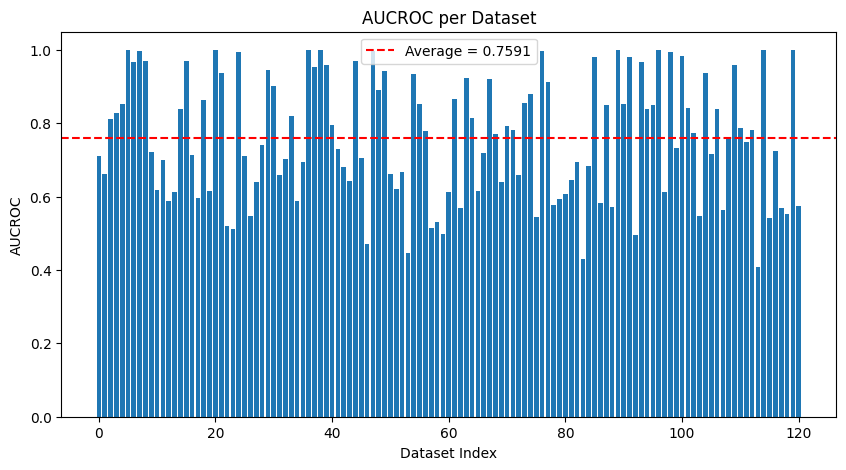

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(range(len(aucroc_scores)), aucroc_scores)
plt.axhline(avg_aucroc, color="red", linestyle="--", label=f"Average = {avg_aucroc:.4f}")
plt.xlabel("Dataset Index")
plt.ylabel("AUCROC")
plt.title("AUCROC per Dataset")
plt.legend()
plt.show()


In [ ]:
aucroc_scores = {}
# Walk through all subdirectories and collect aucroc
for subdir, _, files in os.walk(root_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        dataset_name = os.path.basename(os.path.dirname(subdir))  # e.g. "1_ALOI" or "2_annthyroid"
        df = pd.read_csv(file_path)

        if "aucroc" in df.columns:
            aucroc_scores[dataset_name] = df["aucroc"].values[0]

# Convert to DataFrame for easier handling
results_df = pd.DataFrame(list(aucroc_scores.items()), columns=["Dataset", "AUCROC"])

if not results_df.empty:
    avg_aucroc = results_df["AUCROC"].mean()
    print(results_df)
    print(f"\nNumber of datasets: {len(results_df)}")
    print(f"Average AUCROC: {avg_aucroc:.4f}")

            Dataset    AUCROC
0    23_mammography  0.709984
1            SVHN_5  0.661108
2         40_vowels  0.812888
3     MVTec-AD_tile  0.828667
4      26_optdigits  0.852757
..              ...       ...
116       CIFAR10_0  0.724511
117          SVHN_9  0.568964
118       CIFAR10_5  0.552525
119         45_wine  1.000000
120          SVHN_0  0.575946

[121 rows x 2 columns]

Number of datasets: 121
Average AUCROC: 0.7591


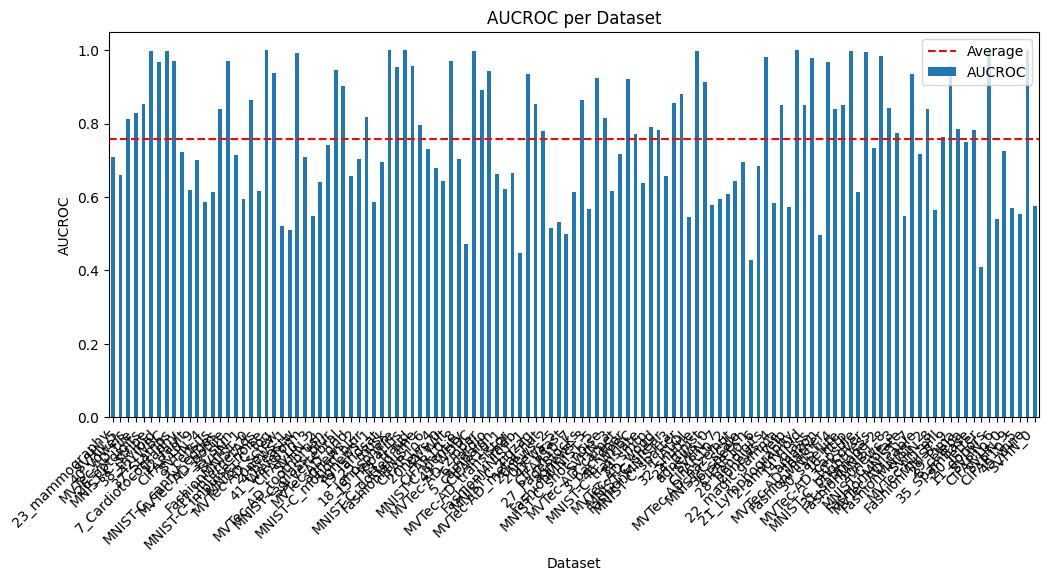

In [30]:
import matplotlib.pyplot as plt

results_df.plot(x="Dataset", y="AUCROC", kind="bar", figsize=(12,5))
plt.axhline(results_df["AUCROC"].mean(), color="red", linestyle="--", label="Average")
plt.title("AUCROC per Dataset")
plt.ylabel("AUCROC")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.show()